# Chapitre 7 - Exercices 7.6 à 7.10

* **7.6** : le nombre effectif de paramètres des $k$ plus proches voisins vaut $N/k$ ;
* **7.7** : le lien entre $C_p$/AIC et la validation croisée généralisée ;
* **7.8** : la famille $\{I(\sin(\alpha x) > 0)\}$ a une dimension VC infinie ;
* **7.9** : sélection du meilleur sous-ensemble sur les données de cancer de la prostate
  par AIC, BIC, validation croisée et bootstrap .632 ;
* **7.10** : la validation croisée avec des prédicteurs binaires très nombreux.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch07_selection as sel
set_style()

## Exercice 7.6 : Degrés de liberté des $k$ plus proches voisins

**Énoncé.** Montrer que, pour un modèle à erreur additive, le nombre effectif de
paramètres de l'ajustement par les $k$ plus proches voisins est $N/k$.

**Rappels.** Le nombre effectif de paramètres est défini par (7.33) :
$\mathrm{df}(\hat{\mathbf y}) = \sum_i\mathrm{Cov}(\hat y_i, y_i)/\sigma^2_\varepsilon$, et vaut
$\mathrm{trace}(\mathbf S)$ pour un lisseur linéaire $\hat{\mathbf y} = \mathbf S\mathbf y$
(exercice 7.5). On suppose les $x_i$ fixés et **distincts**, et l'on note $N_k(x_i)$ les
indices des $k$ points d'apprentissage les plus proches de $x_i$.

**Solution.** Aux points d'apprentissage, l'ajustement s'écrit
$\hat y_i = \frac1k\sum_{j\in N_k(x_i)}y_j$ : c'est un lisseur linéaire de matrice
$S_{ij} = \frac1k I(j\in N_k(x_i))$, qui ne dépend que des $x$. Or $x_i$ est à distance
nulle de lui-même : c'est son propre plus proche voisin, donc $i\in N_k(x_i)$ et
$S_{ii} = 1/k$ pour tout $i$. Ainsi

$$\mathrm{df} = \mathrm{trace}(\mathbf S) = \sum_{i=1}^N\frac1k = \frac Nk.$$

Directement avec (7.33) : les $y_j$ étant indépendants,
$\mathrm{Cov}(\hat y_i, y_i) = \frac1k\sum_{j\in N_k(x_i)}\mathrm{Cov}(y_j, y_i) = \frac1k\mathrm{Var}(y_i) = \frac{\sigma^2_\varepsilon}k$,
et la somme sur $i$ divisée par $\sigma^2_\varepsilon$ redonne $N/k$. $\square$

> **Intuition.** Si les $N$ points se répartissaient en $N/k$ groupes disjoints de $k$
> voisins, les $k$-PPV ajusteraient une constante par groupe : $N/k$ paramètres. La formule
> reste vraie même si les voisinages se chevauchent.

**Vérification numérique** : trace de $\mathbf S$ et estimation par simulation de la
covariance, pour $N = 60$ points de $\mathbb R^2$.

In [2]:
rng = np.random.RandomState(0)
N = 60
X = rng.rand(N, 2)
f = np.sin(3 * X[:, 0]) + X[:, 1]
ks = [1, 2, 3, 4, 5, 6, 10, 12, 15, 20, 30, 60]
df_tr, df_mc = [], []
for k in ks:
    S = sel.knn_smoother_matrix(X, k)
    df_tr.append(sel.df_trace(S))
    df_mc.append(sel.df_monte_carlo(lambda y: sel.knn_regression(X, y, X, k), f, 0.7, n_rep=1500, rng=rng))

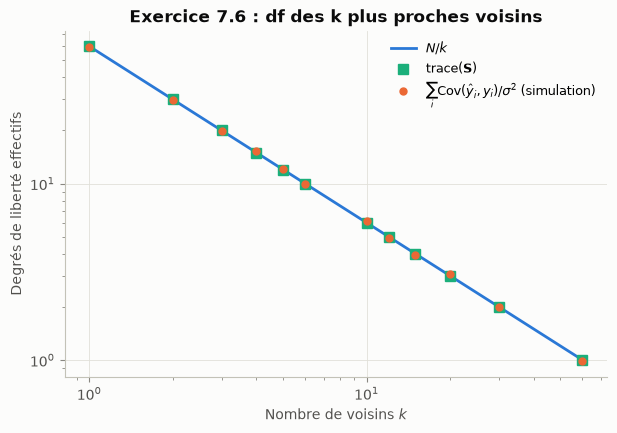

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
kk = np.linspace(1, 60, 300)
ax.plot(kk, N / kk, color=BLUE, label="$N/k$")
ax.plot(ks, df_tr, "s", color=COLORS[2], ms=7, label=r"$\mathrm{trace}(\mathbf{S})$")
ax.plot(ks, df_mc, "o", color=ORANGE, label=r"$\sum_i \mathrm{Cov}(\hat y_i, y_i)/\sigma^2$ (simulation)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de voisins $k$")
ax.set_ylabel("Degrés de liberté effectifs")
ax.set_title("Exercice 7.6 : df des k plus proches voisins")
ax.legend()
plt.show()

> **À retenir.** Pour les $k$-PPV, $S_{ii} = 1/k$ (chaque point est son propre voisin),
> donc $\mathrm{df} = N/k$ : la complexité est inversement proportionnelle à $k$. C'est la
> valeur utilisée pour AIC/BIC dans les figures 7.7 du livre.

## Exercice 7.7 : Relation entre $C_p$/AIC et GCV

**Énoncé.** À l'aide de l'approximation $1/(1-x)^2\approx 1 + 2x$, mettre en évidence la
relation entre $C_p$/AIC (7.26) et la validation croisée généralisée (7.52), la
principale différence étant le modèle utilisé pour estimer la variance du bruit
$\sigma^2_\varepsilon$.

**Rappels.** Pour un lisseur linéaire de degrés de liberté $\mathrm{df} = \mathrm{trace}(\mathbf S)$,
avec $\overline{\mathrm{err}} = \frac1N\sum_i(y_i - \hat f(x_i))^2$ :

$$C_p = \overline{\mathrm{err}} + 2\,\frac{\mathrm{df}}N\,\hat\sigma^2_\varepsilon,
\qquad
\mathrm{GCV} = \frac{\overline{\mathrm{err}}}{\big(1 - \mathrm{df}/N\big)^2}.$$

**Approximation.** Par développement limité de $u\mapsto(1-u)^{-2}$ en $0$ (dérivée
$2(1-u)^{-3}$, qui vaut $2$ en $0$) : $(1-u)^{-2} = 1 + 2u + O(u^2)$. Avec $u = \mathrm{df}/N$
petit (peu de paramètres devant $N$) :

$$\mathrm{GCV}\approx\overline{\mathrm{err}}\Big(1 + 2\frac{\mathrm{df}}N\Big) = \overline{\mathrm{err}} + 2\,\frac{\mathrm{df}}N\,\overline{\mathrm{err}}.$$

**Comparaison.** GCV a donc (au premier ordre) **exactement la forme de $C_p$**, mais avec
$\hat\sigma^2_\varepsilon$ remplacé par $\overline{\mathrm{err}}$, l'erreur d'apprentissage
**du modèle évalué lui-même**. En $C_p$, on estime $\sigma^2_\varepsilon$ une fois pour toutes
à partir d'un modèle peu biaisé (souvent le plus complexe), et la même valeur sert pour
tous les modèles comparés. En GCV, l'estimation change avec le modèle :

* pour un modèle très lisse (biaisé), $\overline{\mathrm{err}}$ surestime $\sigma^2_\varepsilon$ ;
* pour un modèle très flexible, $\overline{\mathrm{err}}$ sous-estime $\sigma^2_\varepsilon$
  (d'un facteur $\approx 1 - \mathrm{df}/N$), mais le facteur exact $(1 - \mathrm{df}/N)^{-2}$
  compense largement.

**Illustration** avec une spline de lissage ($N = 100$) : on trace GCV, son approximation
au premier ordre et $C_p$ avec $\hat\sigma^2_\varepsilon$ tiré d'un ajustement peu biaisé
($\mathrm{df}\approx 30$, $\hat\sigma^2 = N\,\overline{\mathrm{err}}/(N - \mathrm{df})$).

In [4]:
rng = np.random.RandomState(0)
N, sig = 100, 0.5
x = np.sort(rng.rand(N))
y = np.sin(10 * x) * np.exp(-x) + sig * rng.randn(N)
lams = np.logspace(-9, -1, 40)
Ss = [sel.smoothing_spline_matrix(x, l) for l in lams]
dfs = np.array([np.trace(S) for S in Ss])
errs = np.array([np.mean((y - S @ y) ** 2) for S in Ss])
j_low = np.argmin(np.abs(dfs - 30))
s2_hat = N * errs[j_low] / (N - dfs[j_low])
gcv = errs / (1 - dfs / N) ** 2
approx = errs * (1 + 2 * dfs / N)
cp = sel.cp_statistic(errs, dfs, s2_hat, N)
print("sigma^2 estimé (modèle peu biaisé) : %.3f  (vrai : %.3f)" % (s2_hat, sig ** 2))

sigma^2 estimé (modèle peu biaisé) : 0.237  (vrai : 0.250)


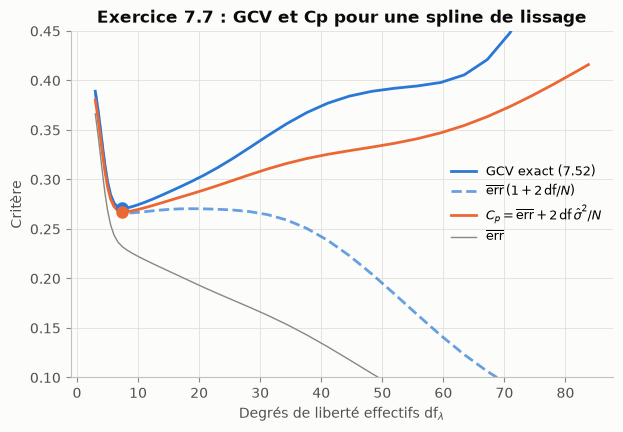

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(dfs, gcv, color=BLUE, label="GCV exact (7.52)")
ax.plot(dfs, approx, "--", color=BLUE, alpha=0.7, label=r"$\overline{\mathrm{err}}\,(1 + 2\,\mathrm{df}/N)$")
ax.plot(dfs, cp, color=ORANGE, label=r"$C_p = \overline{\mathrm{err}} + 2\,\mathrm{df}\,\hat\sigma^2/N$")
ax.plot(dfs, errs, color=GRAY, lw=1, label=r"$\overline{\mathrm{err}}$")
for crit, c in [(gcv, BLUE), (cp, ORANGE)]:
    ax.plot(dfs[crit.argmin()], crit.min(), "o", color=c, ms=8)
ax.set_ylim(0.1, 0.45)
ax.set_xlabel(r"Degrés de liberté effectifs $\mathrm{df}_\lambda$")
ax.set_ylabel("Critère")
ax.set_title("Exercice 7.7 : GCV et Cp pour une spline de lissage")
ax.legend()
plt.show()

Pour des df modérés, GCV, son approximation et $C_p$ sont très proches et désignent des
lissages voisins (points). Quand $\mathrm{df}/N$ grandit, l'approximation linéaire décroche
de GCV, et $C_p$ et GCV divergent car $\overline{\mathrm{err}}$ n'estime plus bien
$\sigma^2_\varepsilon$.

> **À retenir.** Au premier ordre en $\mathrm{df}/N$,
> $\mathrm{GCV}\approx\overline{\mathrm{err}} + 2\frac{\mathrm{df}}N\overline{\mathrm{err}}$ :
> c'est $C_p$/AIC où la variance du bruit est estimée par l'erreur d'apprentissage du
> modèle courant au lieu de celle d'un modèle de référence peu biaisé.

## Exercice 7.8 : La famille $I(\sin(\alpha x) > 0)$ a une dimension VC infinie

**Énoncé.** Montrer que l'ensemble de fonctions $\{I(\sin(\alpha x) > 0)\}$ pulvérise les
points $z_1 = 10^{-1}, \dots, z_\ell = 10^{-\ell}$ de la droite réelle, pour tout $\ell$.
En déduire que la dimension VC de cette classe est infinie.

**Rappels.** Pulvériser $\{z_1, \dots, z_\ell\}$ signifie : pour **chacun** des $2^\ell$
étiquetages $(y_1, \dots, y_\ell)\in\{0,1\}^\ell$, il existe $\alpha$ tel que
$I(\sin(\alpha z_j) > 0) = y_j$ pour tout $j$. On utilise que $\sin t > 0$ si et seulement
si $t \bmod 2\pi\in\,]0, \pi[$, autrement dit si $t/\pi \bmod 2\in\,]0, 1[$.

**Construction.** Étant donné l'étiquetage, on pose

$$\alpha = \pi\Big(1 + \sum_{i=1}^\ell(1 - y_i)\,10^{i}\Big).$$

Fixons $j$ et calculons $\alpha z_j/\pi = 10^{-j} + \sum_{i=1}^\ell(1 - y_i)10^{i-j}$. On
sépare la somme en trois parties :

* $i > j$ : $10^{i-j}$ est un entier **pair** (multiple de 10), donc ces termes ne changent
  pas $\alpha z_j/\pi$ modulo 2 ;
* $i = j$ : le terme vaut $(1 - y_j)\in\{0, 1\}$ ;
* $i < j$ (avec le terme $10^{-j}$) : leur somme
  $\varepsilon_j = 10^{-j} + \sum_{i<j}(1 - y_i)10^{i-j}$ vérifie
  $0 < \varepsilon_j\leq\sum_{m=1}^{\infty}10^{-m} = 1/9 < 1$.

Ainsi $\alpha z_j/\pi\equiv(1 - y_j) + \varepsilon_j\pmod 2$ avec $\varepsilon_j\in\,]0, 1[$ :

* si $y_j = 1$ : $\alpha z_j/\pi\equiv\varepsilon_j\in\,]0, 1[$, donc $\sin(\alpha z_j) > 0$ et
  l'indicatrice vaut $1$ ;
* si $y_j = 0$ : $\alpha z_j/\pi\equiv 1 + \varepsilon_j\in\,]1, 2[$, donc $\sin(\alpha z_j) < 0$
  et l'indicatrice vaut $0$.

Tout étiquetage est donc réalisé : les $\ell$ points sont pulvérisés. Comme c'est vrai pour
**tout** $\ell$, aucun entier ne majore le nombre de points pulvérisables : la dimension
VC est infinie, bien que la classe n'ait qu'**un seul** paramètre. $\square$

**Vérification numérique.** Pour de grands $\ell$, $\alpha\approx 10^\ell$ et le calcul de
$\sin(\alpha z_j)$ en flottants perd toute précision. On calcule donc les phases
$\alpha z_j/\pi\bmod 2$ en **arithmétique rationnelle exacte** (`sel.sin_shatter_phases`),
et l'on vérifie tous les étiquetages pour $\ell\leq 12$ ($2^{12} = 4096$ étiquetages).

In [ ]:
import itertools
for l in [1, 2, 4, 8, 12]:
    ok = all(np.array_equal(((ph := sel.sin_shatter_phases(lab)) > 0) & (ph < 1), np.array(lab, bool))
             for lab in itertools.product([0, 1], repeat=l))
    print("l = %2d : les %5d étiquetages sont réalisés : %s" % (l, 2 ** l, ok))
rng = np.random.RandomState(0)
lab40 = rng.randint(0, 2, 40)
ph = sel.sin_shatter_phases(lab40)
print("l = 40, étiquetage aléatoire réalisé :", np.array_equal((ph > 0) & (ph < 1), lab40.astype(bool)))

Visualisons un exemple avec $\ell = 3$ et l'étiquetage $(y_1, y_2, y_3) = (1, 0, 1)$ : on
trouve $\alpha = \pi(1 + 10^2) = 101\pi$. On trace $\sin(\alpha x)$ en échelle logarithmique
en $x$ pour voir les trois points.